<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

========== Regression Evaluation ==========
Mean Absolute Error (MAE): 979679.69
Mean Squared Error (MSE): 1771751116594.04
Root Mean Squared Error (RMSE

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


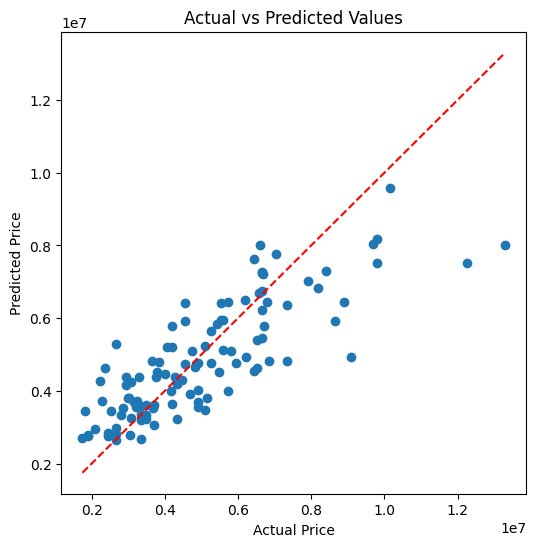

In [1]:
# EXERCISE - 03 (MULTIPLE LINEAR REGRESSION)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    explained_variance_score,
    max_error
)

data = '/content/Housing.csv'

df= pd.read_csv(data)

df.head()

df.info()

le = LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

X = df.drop("price", axis=1)
y = df["price"]

x1, x2, y1, y2 = train_test_split(X, y,test_size=0.2,random_state=42)

model = LinearRegression()
model.fit(x1, y1)

y_pred = model.predict(x2)
y_pred

mae = mean_absolute_error(y2, y_pred)
mse = mean_squared_error(y2, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y2, y_pred)
mape = mean_absolute_percentage_error(y2, y_pred)
evs = explained_variance_score(y2, y_pred)
maxerr = max_error(y2, y_pred)

n = x2.shape[0]      # Number of observations
p = x2.shape[1]      # Number of predictors

adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("\n========== Regression Evaluation ==========")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")
print(f"Adjusted R² Score: {adj_r2:.4f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.4f}")
print(f"Explained Variance Score: {evs:.4f}")
print(f"Maximum Error: {maxerr:.2f}")

print("\nIntercept:")
print(model.intercept_)


# In[21]:


print("\nCoefficients:")
coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print(coef)

new_house = [[5000,3,2,2,1,1,0,1,0,1,0,1]]

prediction = model.predict(new_house)

print("\nPredicted House Price:", prediction[0])

import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(y2, y_pred)
plt.plot([y2.min(), y2.max()],
         [y2.min(), y2.max()],
         'r--')


plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Values")
plt.show()